In [27]:
# Import libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
pd.options.display.float_format = '{:.5f}'.format
from sklearn.preprocessing import OneHotEncoder
from category_encoders import CountEncoder
from category_encoders.target_encoder import TargetEncoder

%matplotlib inline
import warnings
warnings.filterwarnings('ignore')


from sklearn.metrics import mean_absolute_error
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.linear_model import LinearRegression,Ridge,LogisticRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.neighbors import KNeighborsRegressor
from xgboost import XGBRegressor
from lightgbm import LGBMRegressor


In [28]:
train = pd.read_csv('../data/train.csv')
policies = pd.read_csv('../data/policies.csv')
test = pd.read_csv('../data/test.csv')
samplesubmission = pd.read_csv('../data/SampleSubmission.csv')

In [29]:
features  = ['sum_insured', 'product',
       'agent', 'class_of_business', 'risk_type', 'loss_date', 'client_type',
       'renewal_frequency', 'primary_cause', 'secondary_cause', 'branch']

In [30]:
categorical = ['product',
       'agent', 'class_of_business', 'risk_type', 'client_type',
       'renewal_frequency', 'primary_cause', 'secondary_cause', 'branch']

In [31]:
data  = pd.concat([train,test],axis=0)

In [32]:
data.shape

(13395, 15)

In [33]:
for col in categorical:
    data = pd.concat([data,pd.get_dummies(data[col],drop_first=True)] ,axis=1)

In [34]:
data.shape

(13395, 254)

In [35]:
# Convert datetime variables to datetime objects
data.loss_date = pd.to_datetime(data.loss_date, errors='coerce')

# Confirm that the dates have been converted successfully 
data.loss_date.describe()

# Extract day, month and year from the loss date column
# day
data['loss_date_day'] = data.loss_date.dt.day

# month
data['loss_date_month'] = data.loss_date.dt.month
 
# year
data['loss_date_year'] = data.loss_date.dt.year

# Preview engineered date features
data[['loss_date', 'loss_date_day', 'loss_date_month', 'loss_date_year']].head()

,loss_date,loss_date_day,loss_date_month,loss_date_year
0,2021-05-13,13,5,2021
1,2018-05-13,13,5,2018
2,2018-08-18,18,8,2018
3,2018-12-20,20,12,2018
4,2018-11-07,7,11,2018


In [36]:
train = data[:9376]
test = data[9376:]
print(train.shape)
print(test.shape)

(9376, 257)
(4019, 257)


In [37]:
data.shape

(13395, 257)

In [38]:
to_encode = ['product','risk_type']
cEncoder = CountEncoder(cols=to_encode)
cEncoder.fit(train[to_encode],train.target)
train = train.join(cEncoder.transform(train[to_encode]).add_suffix('_count'))
# cEncoder.fit(test[to_encode])
test = test.join(cEncoder.transform(test[to_encode]).add_suffix('_count'))

In [39]:
train.shape

(9376, 259)

In [40]:
train.columns.to_list()

['claim_id',
 'policy_number',
 'claim_number',
 'sum_insured',
 'product',
 'agent',
 'class_of_business',
 'risk_type',
 'loss_date',
 'client_type',
 'renewal_frequency',
 'primary_cause',
 'secondary_cause',
 'branch',
 'target',
 'prod00002',
 'prod00003',
 'prod00004',
 'prod00005',
 'prod00006',
 'prod00007',
 'prod00008',
 'prod00009',
 'prod00010',
 'prod00011',
 'prod00012',
 'prod00013',
 'prod00014',
 'prod00015',
 'prod00016',
 'prod00017',
 'prod00018',
 'prod00019',
 'prod00020',
 'prod00021',
 'prod00022',
 'prod00023',
 'prod00024',
 'prod00025',
 'prod00026',
 'prod00027',
 'prod00028',
 'prod00029',
 'prod00030',
 'prod00031',
 'prod00032',
 'prod00033',
 'prod00034',
 'prod00035',
 'prod00036',
 'prod00037',
 'ag00037',
 'ag00044',
 'ag00064',
 'ag00068',
 'ag00080',
 'ag00083',
 'ag00226',
 'cob00002',
 'cob00003',
 'cob00004',
 'cob00005',
 'cob00006',
 'cob00007',
 'cob00008',
 'cob00009',
 'cob00010',
 'cob00011',
 'cob00012',
 'cob00013',
 'cob00014',
 'cob0001

In [41]:
feature_cols = [col for col in train.columns if col not in ['claim_id', 'policy_number', 'claim_number','product', 'agent', 'class_of_business', 'risk_type', 'loss_date', 'client_type', 'renewal_frequency', 'primary_cause', 'secondary_cause', 'branch','target']]

# feature_cols

In [42]:

X = train[feature_cols]
y = train.target

# Split data into train and test sets
X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.5, random_state=123)

# Train model
model = LinearRegression()
model.fit(X, y)
# model.fit(X_train, y_train)

# Make predictions
# y_pred = model.predict(X_test)

# Check the MAE score of the model
# print(f'LinearRegression MAE score on the X_test is: {mean_absolute_error(y_test, y_pred)}')

LinearRegression()

In [43]:

# Train model2
model2 = Ridge()
model2.fit(X, y)

# Make predictions
# y_pred2 = model2.predict(X_test)

# Check the MAE score of the model
# print(f'LinearRegression MAE score on the X_test is: {mean_absolute_error(y_test, y_pred)}')

Ridge()

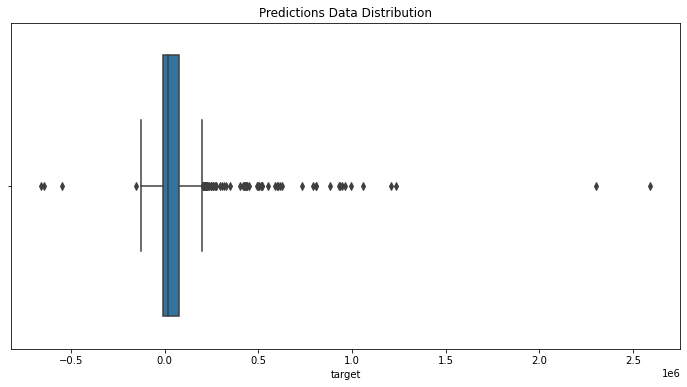

In [44]:
# Make prediction on the test set
test_df = test[feature_cols]
predictions = model.predict(test_df)

# # Create a submission file
sub_file = samplesubmission.copy()
sub_file.target = predictions

# Check the distribution of your predictions
plt.figure(figsize=(12, 6))
sns.boxplot(sub_file.target)
plt.title('Predictions Data Distribution')

# Write to csv file to submit to Zindi
sub_file.to_csv("LinearCCenc.csv", index = False)

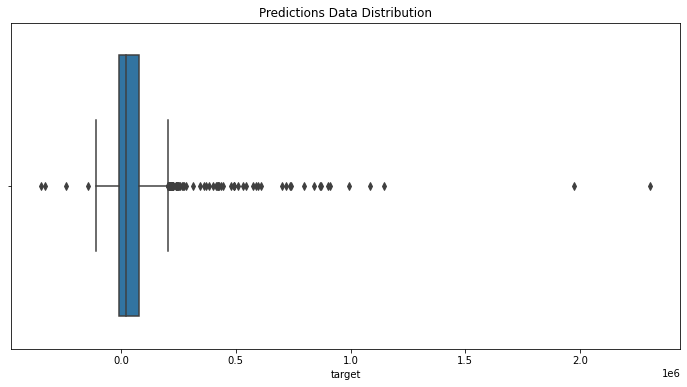

In [45]:
# Make prediction on the test set
test_df = test[feature_cols]
predictions2 = model2.predict(test_df)

# # Create a submission file
sub_file = samplesubmission.copy()
sub_file.target = predictions2

# Check the distribution of your predictions
plt.figure(figsize=(12, 6))
sns.boxplot(sub_file.target)
plt.title('Predictions Data Distribution')

# Write to csv file to submit to Zindi
sub_file.to_csv("RidgeCCenc.csv", index = False)

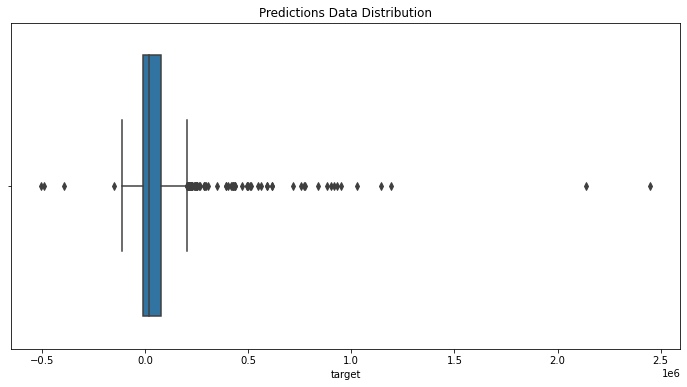

In [46]:
blend = predictions * .5 + predictions2 * .5

sub_file.target = blend

# Check the distribution of your predictions
plt.figure(figsize=(12, 6))
sns.boxplot(sub_file.target)
plt.title('Predictions Data Distribution')

# Write to csv file to submit to Zindi
sub_file.to_csv("BLEND.csv", index = False)

In [47]:
# meta = pd.DataFrame()
# meta['col1'] = y_pred
# meta['col2'] = y_pred2
# meta_model = LinearRegression()
# meta_model.fit(test_df.join[],y_test)




# # Make prediction on the test set
# test_df = test[feature_cols]
# meta_prediction = meta_model.predict(test_df)

# # # Create a submission file
# sub_file = samplesubmission.copy()
# sub_file.target = meta_prediction

# # Check the distribution of your predictions
# plt.figure(figsize=(12, 6))
# sns.boxplot(sub_file.target)
# plt.title('Predictions Data Distribution')

# # Write to csv file to submit to Zindi
# sub_file.to_csv("META.csv", index = False)

In [48]:
model2.feature_importances_.plot()

AttributeError: 'Ridge' object has no attribute 'feature_importances_'